# Perhitungan Volume Kedua Lambung Kapal Terbaru (setelah revisi)

**Mata Kuliah:** Analisis Numerik  
**Topik:** Perhitungan Volume  
**Nama:** Oline Ola Fadhillah 
**NPM:** 25083010028
**Kelas:** A

Link Repository GitHub : [(https://github.com/olineola6/25083010028_Oline-Ola-Fadhillah_All-Tugas-Analisis-Numerik)]

## 1. Setup dan Kalibrasi Skala

**Tujuan:** mengubah ukuran di gambar (piksel) menjadi ukuran nyata (cm/meter).
Semua perhitungan volume, massa, CoM, dan CoB nanti bergantung pada skala ini,
karena volume ∝ (skala)³.

**Langkah:**
1. Render halaman gambar perahu dari PDF.
2. Deteksi otomatis garis grid hijau (vertikal dan horizontal).
3. Hitung ukuran 1 kotak dalam piksel, lalu ubah ke cm.
4. Cek silang: berapa pola dash+kosong (5+5 cm) dalam 1 kotak?


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Ukuran gambar      : 2205 x 1241 piksel
Garis grid         : 21 vertikal, 16 horizontal
1 kotak            : 71.17 piksel  = 45 cm
Skala              : 1 piksel = 0.632 cm
Lebar grid         : 20 kotak = 9.0 m

Cek kalibrasi      : 1 kotak = 4.31 pola dash+kosong  (asumsi soal: 4,5)
Jika 1 pola = 10 cm: 1 kotak = 43.1 cm


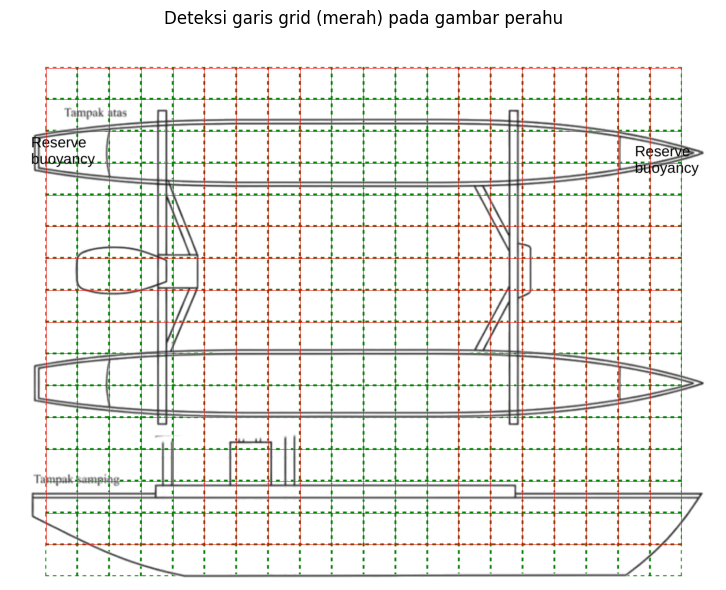

In [7]:
!pip install pymupdf
import numpy as np
import matplotlib.pyplot as plt
import fitz  # PyMuPDF

PDF_PATH = "perahu.pdf"
DPI      = 200
CELL_CM  = 45.0     # instruksi dosen: 1 kotak = 45 cm

def render(dpi):
    """Render halaman 1 PDF menjadi array RGB (tinggi x lebar x 3)."""
    pix = fitz.open(PDF_PATH)[0].get_pixmap(dpi=dpi, alpha=False)
    return np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, 3).astype(int)

img = render(DPI)
R, G, B = img[..., 0], img[..., 1], img[..., 2]
hijau = (G - R > 40) & (G - B > 40)          # mask piksel garis grid

def cari_garis(proyeksi, ambang=0.4, celah=3):
    idx = np.where(proyeksi > proyeksi.max() * ambang)[0]
    hasil, awal, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev > celah:
            hasil.append((awal + prev) / 2); awal = i
        prev = i
    hasil.append((awal + prev) / 2)
    return np.array(hasil)

gx = cari_garis(hijau.sum(axis=0))           # garis vertikal   -> posisi x (px)
gy = cari_garis(hijau.sum(axis=1))           # garis horizontal -> posisi y (px)
S  = (gx[-1] - gx[0]) / (len(gx) - 1)        # piksel per kotak

print(f"Ukuran gambar      : {img.shape[1]} x {img.shape[0]} piksel")
print(f"Garis grid         : {len(gx)} vertikal, {len(gy)} horizontal")
print(f"1 kotak            : {S:.2f} piksel  = {CELL_CM:.0f} cm")
print(f"Skala              : 1 piksel = {CELL_CM/S:.3f} cm")
print(f"Lebar grid         : {(len(gx)-1)} kotak = {(len(gx)-1)*CELL_CM/100:.1f} m")

# cek silang: berapa pola dash+kosong dalam 1 kotak? (DPI 400 supaya dash jelas)
big = render(400)
hb  = (big[..., 1] - big[..., 0] > 40) & (big[..., 1] - big[..., 2] > 40)
x   = int(round(cari_garis(hb.sum(axis=0), celah=6)[-2]))
kol = hb[:, x-3:x+4].any(axis=1).astype(int)
awal = np.where(np.diff(np.concatenate([[0], kol])) == 1)[0]
periode = np.median(np.diff(awal)[np.diff(awal) < 40])
print(f"\nCek kalibrasi      : 1 kotak = {S*2/periode:.2f} pola dash+kosong  (asumsi soal: 4,5)")
print(f"Jika 1 pola = 10 cm: 1 kotak = {S*2/periode*10:.1f} cm")

# visual: garis grid yang terdeteksi
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(img.astype(np.uint8))
for v in gx: ax.plot([v, v], [gy[0], gy[-1]], color="red", lw=.5, alpha=.7)
for h in gy: ax.plot([gx[0], gx[-1]], [h, h], color="red", lw=.5, alpha=.7)
ax.set_xlim(gx[0]-80, gx[-1]+80); ax.set_ylim(gy[-1]+80, gy[0]-80)
ax.set_title("Deteksi garis grid (merah) pada gambar perahu"); ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretasi**
- Terdeteksi 21 garis grid vertikal, artinya grid selebar 20 kotak. Satu kotak = 71,17 piksel.
  Dengan 1 kotak = 45 cm, skalanya 1 piksel ≈ 0,63 cm, dan lebar grid ≈ 9 m.
- Skala yang dipakai: **1 kotak = 45 cm** (sesuai instruksi dosen). Karena 1 pola dash+kosong
  = 5+5 = 10 cm, ini setara 4,5 pola per kotak.
- Cek silang pada render PDF memberi ±4,3 pola per kotak (≈ 43 cm). Selisihnya kecil dan
  dianggap wajar akibat rendering, jadi angka dosen tetap dipakai.
- Skala menentukan semua hasil berikutnya. Volume sebanding dengan (skala)³, sehingga selisih
  45 vs 43 cm saja bisa mengubah volume sekitar 13%. Karena itu `CELL_CM` dijadikan satu
  parameter, dan pengaruh skala terhadap hasil dibahas lagi pada kesimpulan.
- Langkah berikutnya memakai skala ini untuk mengubah posisi piksel garis lambung
  menjadi lebar w(x) dan kedalaman d(x) dalam meter.

## 2. Digitalisasi Lebar w(x) dan Kedalaman d(x)

**Tujuan:** mengubah gambar menjadi data angka. Dari tampak atas kita ukur lebar
lambung w(x), dari tampak samping kita ukur kedalaman d(x), di sepanjang sumbu x.
Karena lantai datar (tanpa keel), potongan melintang lambung berbentuk persegi
panjang, sehingga luas penampangnya A(x) = w(x)·d(x) (dipakai di Langkah 3).

**Langkah:**
1. Tetapkan batas hitung di garis *reserve buoyancy*: x = 2 sampai x = 18 kotak
   (bagian di luar itu tidak dihitung). Titik ukur tiap 0,125 kotak.
2. Cari garis tengah tiap lambung (di x = 8 kotak, bagian lurus dan bersih).
   Lebar w = 2 × jarak tepi luar ke garis tengah (lambung simetris).
3. Cari garis geladak di tampak samping. Kedalaman d = jarak geladak ke dasar lambung.
4. Titik yang tertutup balok melintang atau tulisan dibuang, lalu diganti nilai
   lambung kembarnya (atau interpolasi bila keduanya terganggu).

Pusat lambung 1: y=212.0px | lambung 2: y=728.0px | geladak: y=973.0px
Jarak antar pusat lambung = 3.26 m
Titik ukur: 129 titik, x = 2 s/d 18 kotak (panjang 7.2 m)
Titik terganggu diperbaiki: lambung 1 = 14, lambung 2 = 13
Beda maks lebar lambung 1 vs 2 = 3.8 cm

 x (m)  w1 (m)  w2 (m)   d (m)
  0.00   0.847   0.847   0.866
  0.45   0.872   0.872   1.031
  0.90   0.923   0.923   1.157
  1.35   0.961   0.961   1.189
  1.80   0.961   0.974   1.189
  2.25   0.961   0.974   1.189
  2.70   0.961   0.974   1.189
  3.15   0.961   0.974   1.189
  3.60   0.974   0.974   1.189
  4.05   0.974   0.974   1.182
  4.50   0.974   0.974   1.182
  4.95   0.961   0.974   1.182
  5.40   0.961   0.936   1.182
  5.85   0.923   0.923   1.182
  6.30   0.872   0.835   1.182
  6.75   0.746   0.746   1.182
  7.20   0.620   0.607   1.182


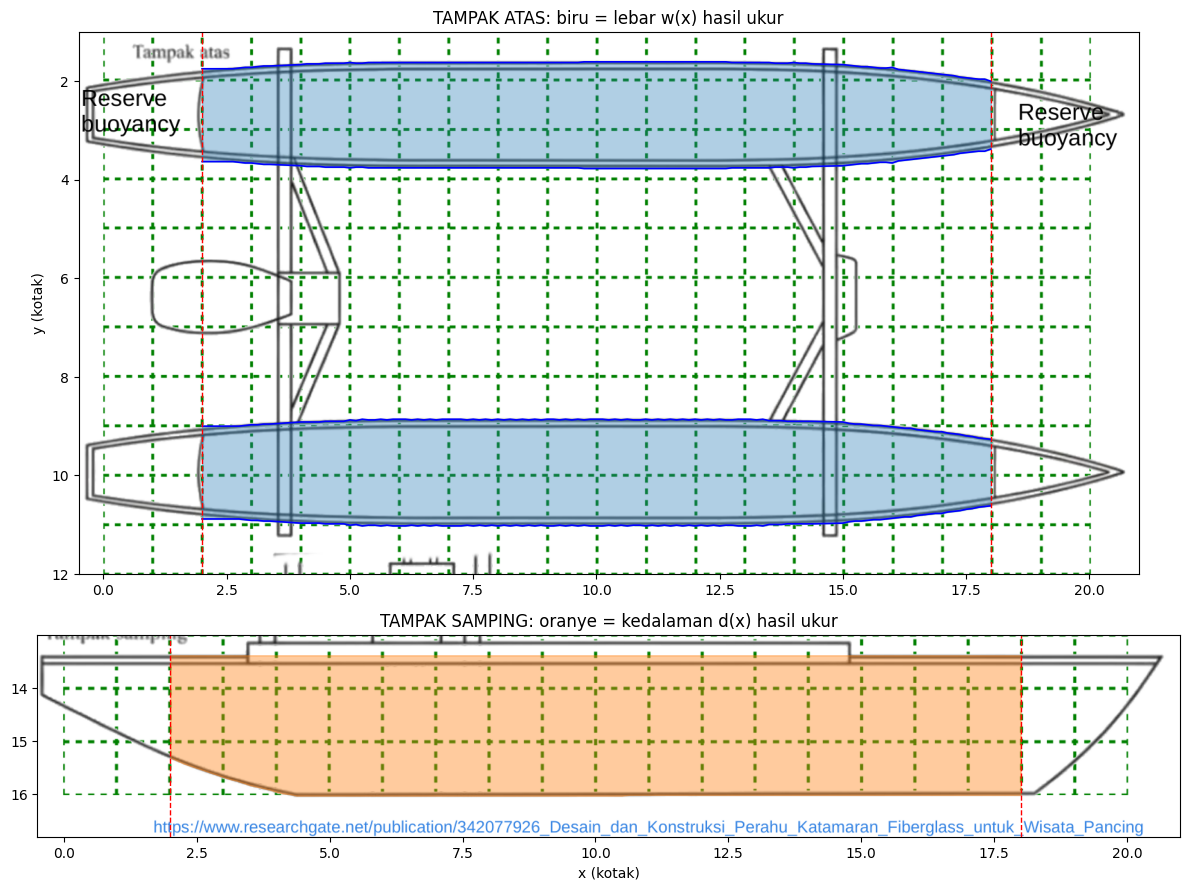

In [8]:
X_A, X_B, STEP = 2.0, 18.0, 0.125        # batas hitung = garis reserve buoyancy; jarak titik ukur
Y0 = gy[0]
gelap = ((R+G+B)/3 < 200) & ~hijau & (abs(R-G) < 35) & (abs(G-B) < 35)   # piksel garis lambung (abu/hitam)

def r(k): return int(round(Y0 + k*S))           # baris piksel dari posisi vertikal (kotak)
def c(x): return int(round(gx[0] + x*S))        # kolom piksel dari posisi horizontal (kotak)
def tepi_atas(px, y0, y1):
    ys = np.where(gelap[y0:y1, px])[0]; return ys[0] + y0 if len(ys) else np.nan
def tepi_bawah(px, y0, y1):
    ys = np.where(gelap[y0:y1, px])[0]; return ys[-1] + y0 if len(ys) else np.nan

# garis tengah tiap lambung (diukur di x = 8 kotak) dan garis geladak
Z1, Z2 = (r(1.3), r(4.5)), (r(8.6), r(11.6))
CY1 = (tepi_atas(c(8), *Z1) + tepi_bawah(c(8), *Z1)) / 2
CY2 = (tepi_atas(c(8), *Z2) + tepi_bawah(c(8), *Z2)) / 2
DECK = np.median([tepi_atas(c(x), r(13.0), r(16.6)) for x in np.arange(16, 17.5, .25)])

xs = np.arange(X_A, X_B + 1e-9, STEP)
w1, w2, d = (np.zeros(len(xs)) for _ in range(3))
b1, b2 = (np.zeros(len(xs), bool) for _ in range(2))
for i, x in enumerate(xs):
    px = c(x)
    w1[i] = 2 * (CY1 - tepi_atas(px, r(1.3), int(CY1))) / S      # lebar = 2 x jarak tepi luar ke garis tengah
    w2[i] = 2 * (tepi_bawah(px, int(CY2), r(11.6)) - CY2) / S
    d[i]  = (tepi_bawah(px, r(14.0), r(16.6)) - DECK) / S        # kedalaman = geladak -> dasar lambung
    b1[i] = gelap[r(1.45):r(1.55), px-6:px+7].any()              # terganggu balok/tulisan (lambung 1)
    b2[i] = gelap[r(11.05):r(11.2), px-6:px+7].any()             # terganggu balok (lambung 2)

# perbaikan titik terganggu: pakai lambung kembar bila bersih, selain itu interpolasi
bad1 = b1 | (np.abs(w1 - w2) > 0.12);  bad2 = b2 | (np.abs(w1 - w2) > 0.12)
w1c = np.where(bad1 & ~bad2, w2, w1);  w2c = np.where(bad2 & ~bad1, w1, w2)
both = bad1 & bad2
w1c[both] = np.interp(xs[both], xs[~both], w1[~both]); w2c[both] = np.interp(xs[both], xs[~both], w2[~both])
w1, w2 = w1c, w2c

cm = CELL_CM
print(f"Pusat lambung 1: y={CY1:.1f}px | lambung 2: y={CY2:.1f}px | geladak: y={DECK:.1f}px")
print(f"Jarak antar pusat lambung = {(CY2-CY1)/S*cm/100:.2f} m")
print(f"Titik ukur: {len(xs)} titik, x = {X_A:g} s/d {X_B:g} kotak (panjang {(X_B-X_A)*cm/100:.1f} m)")
print(f"Titik terganggu diperbaiki: lambung 1 = {bad1.sum()}, lambung 2 = {bad2.sum()}")
print(f"Beda maks lebar lambung 1 vs 2 = {np.abs(w1-w2).max()*cm:.1f} cm")
print(f"\n{'x (m)':>6} {'w1 (m)':>7} {'w2 (m)':>7} {'d (m)':>7}")
for k in range(0, len(xs), 8):
    print(f"{(xs[k]-X_A)*cm/100:6.2f} {w1[k]*cm/100:7.3f} {w2[k]*cm/100:7.3f} {d[k]*cm/100:7.3f}")

# visual: hasil ukur di atas gambar asli
H, W = img.shape[:2]
ext = lambda y0, y1: [(0-gx[0])/S, (W-gx[0])/S, (y1-Y0)/S, (y0-Y0)/S]
yc = lambda py: (py - Y0) / S
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={"height_ratios": [3, 1.2]})
a1.imshow(img[r(1):r(12)].astype(np.uint8), extent=ext(r(1), r(12)))
for ctr, w in [(CY1, w1), (CY2, w2)]:
    a1.fill_between(xs, yc(ctr)-w/2, yc(ctr)+w/2, color="tab:blue", alpha=.35)
    a1.plot(xs, yc(ctr)-w/2, "b-", lw=1.2); a1.plot(xs, yc(ctr)+w/2, "b-", lw=1.2)
a1.set_xlim(-0.5, 21); a1.set_title("TAMPAK ATAS: biru = lebar w(x) hasil ukur"); a1.set_ylabel("y (kotak)")
a2.imshow(img[r(13):r(16.8)].astype(np.uint8), extent=ext(r(13), r(16.8)))
a2.fill_between(xs, yc(DECK), yc(DECK + d*S), color="tab:orange", alpha=.4)
a2.set_xlim(-0.5, 21); a2.set_title("TAMPAK SAMPING: oranye = kedalaman d(x) hasil ukur"); a2.set_xlabel("x (kotak)")
for a in (a1, a2):
    for xv in (X_A, X_B): a.axvline(xv, color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

**Interpretasi**
- Lambung diukur sepanjang **7,2 m** (x = 2 sampai 18 kotak) dengan 129 titik ukur.
  Bentuknya hampir balok di bagian tengah: lebar maksimum **≈ 0,97 m** dan kedalaman
  maksimum **≈ 1,19 m**, keduanya nyaris konstan dari x ≈ 1,35 m sampai ≈ 5 m.
- Menuju **haluan** (x = 7,2 m) lebar mengecil menjadi ≈ 0,61 m karena lambung meruncing.
  Menuju **buritan** (x = 0) kedalaman mengecil menjadi ≈ 0,87 m karena dasar lambung
  melengkung naik, sedangkan lebarnya masih ≈ 0,85 m.
- Lebar lambung 1 dan lambung 2 hampir sama: beda maksimum hanya **3,8 cm**
  (sekitar 6 piksel pada skala ini). Jadi kedua lambung dapat dianggap **identik**,
  dan ini mendukung asumsi bahwa lambung simetris terhadap garis tengahnya.
- Titik yang tertutup balok melintang atau tulisan (14 titik di lambung 1, 13 titik
  di lambung 2) sudah diperbaiki dengan nilai lambung kembar atau interpolasi. Karena
  bentuk lambung mulus di bagian itu, pengaruhnya ke hasil kecil.
- Jarak antar pusat lambung ≈ 3,26 m. Angka ini tidak dipakai untuk volume, tetapi
  penting nanti untuk posisi CoM dan CoB kapal secara keseluruhan.
- Sumber galat: ±1 piksel ≈ 0,6 cm. Selisih kecil antara dua lambung (hingga 3,8 cm)
  adalah galat digitalisasi, bukan perbedaan bentuk yang sebenarnya.
- Data w(x) dan d(x) ini yang diintegralkan pada Langkah 3 lewat A(x) = w(x)·d(x).

## 3. Luas Penampang A(x) dan Volume Lambung (Integral Numerik)

**Tujuan:** menghitung volume tiap lambung dari data w(x) dan d(x) di Langkah 2.

**Teori:** karena lantai datar (tanpa keel), potongan melintang di setiap posisi x
berbentuk persegi panjang, sehingga luas penampangnya

$$A(x) = w(x)\cdot d(x), \qquad V = \int_{x_a}^{x_b} A(x)\,dx$$

Integral ini dihitung numerik dengan membagi lambung menjadi $n$ pias selebar $h$:

- **Trapesium** (galat $O(h^2)$):
  $V \approx \frac{h}{2}\left[A_0 + 2\sum_{i=1}^{n-1}A_i + A_n\right]$
- **Simpson 1/3** (galat $O(h^4)$, $n$ harus genap):
  $V \approx \frac{h}{3}\left[A_0 + 4\sum_{\text{ganjil}}A_i + 2\sum_{\text{genap}}A_i + A_n\right]$

**Langkah:**
1. Hitung A(x) = w(x)·d(x) untuk kedua lambung.
2. Kerjakan satu lambung secara rinci dengan h = 1 kotak (16 pias) dalam bentuk tabel.
3. Uji konvergensi: perkecil h dan lihat apakah hasilnya stabil.
4. Bandingkan dengan Cubic Spline sebagai pembanding independen.
5. Hitung volume kedua lambung.

 i  x (m)   A (m²)  koef   koef×A
 0   0.00   0.7338     1   0.7338
 1   0.45   0.8992     4   3.5966
 2   0.90   1.0680     2   2.1360
 3   1.35   1.1423     4   4.5691
 4   1.80   1.1423     2   2.2846
 5   2.25   1.1423     4   4.5691
 6   2.70   1.1423     2   2.2846
 7   3.15   1.1423     4   4.5691
 8   3.60   1.1573     2   2.3146
 9   4.05   1.1512     4   4.6046
10   4.50   1.1512     2   2.3023
11   4.95   1.1362     4   4.5448
12   5.40   1.1362     2   2.2724
13   5.85   1.0914     4   4.3654
14   6.30   1.0316     2   2.0631
15   6.75   0.8821     4   3.5282
16   7.20   0.7326     1   0.7326

Σ(koef×A) = 51.4709
Simpson 1/3 = (0.45/3) × 51.4709 = 7.7206 m³
Trapesium   = 7.7169 m³

 h (cm)  pias  Trapesium   Simpson  |Simp - ref|
   90.0     8     7.7058    7.7730       0.06909
   45.0    16     7.7169    7.7206       0.01676
   22.5    32     7.7139    7.7129       0.00907
   11.2    64     7.7075    7.7054       0.00150
    5.6   128     7.7048    7.7039       0.00000
Pem

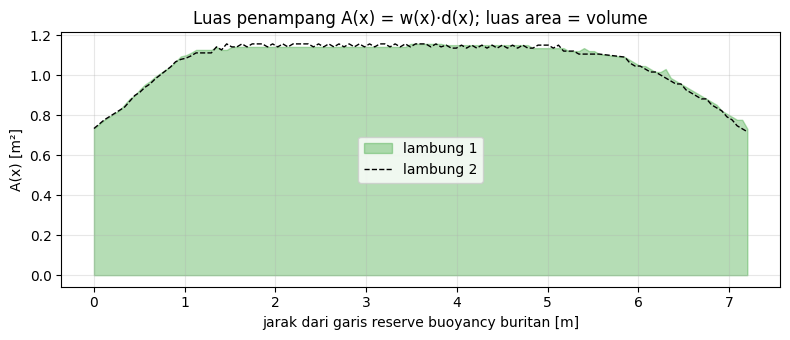

In [10]:
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

cm = CELL_CM
xm = (xs - X_A) * cm / 100            # posisi sepanjang lambung [m]
W1, W2, D = w1*cm/100, w2*cm/100, d*cm/100
A1, A2 = W1*D, W2*D                   # luas penampang [m^2]

def trapesium(a, h): return h * (a.sum() - 0.5*(a[0] + a[-1]))
def ambil(a, h_kotak):                # ambil tiap k titik -> pias selebar h_kotak
    k = int(round(h_kotak/STEP)); return a[::k], h_kotak*cm/100

# tabel perhitungan manual: h = 1 kotak (16 pias)
a, h = ambil(A1, 1.0); n = len(a) - 1
koef = np.array([1] + [4 if i % 2 else 2 for i in range(1, n)] + [1])
print(f"{'i':>2} {'x (m)':>6} {'A (m²)':>8} {'koef':>5} {'koef×A':>8}")
for i in range(n+1):
    print(f"{i:>2} {i*h:6.2f} {a[i]:8.4f} {koef[i]:5d} {koef[i]*a[i]:8.4f}")
V_simp = h/3*(koef*a).sum(); V_trap = trapesium(a, h)
print(f"\nΣ(koef×A) = {(koef*a).sum():.4f}")
print(f"Simpson 1/3 = ({h:.2f}/3) × {(koef*a).sum():.4f} = {V_simp:.4f} m³")
print(f"Trapesium   = {V_trap:.4f} m³")

# uji konvergensi
V_ref = simpson(A1, dx=STEP*cm/100)
print(f"\n{'h (cm)':>7} {'pias':>5} {'Trapesium':>10} {'Simpson':>9} {'|Simp - ref|':>13}")
for hk in [2, 1, 0.5, 0.25, 0.125]:
    a, h = ambil(A1, hk)
    print(f"{hk*cm:7.1f} {len(a)-1:5d} {trapesium(a,h):10.4f} {simpson(a,dx=h):9.4f} {abs(simpson(a,dx=h)-V_ref):13.5f}")
V_spl = CubicSpline(xm, A1).integrate(xm[0], xm[-1])
print(f"Pembanding Cubic Spline = {V_spl:.4f} m³")

# hasil kedua lambung
V1, V2 = simpson(A1, dx=STEP*cm/100), simpson(A2, dx=STEP*cm/100)
print("="*52)
print(f"Volume lambung 1 : {V1:7.3f} m³ = {V1*1000:7.0f} liter")
print(f"Volume lambung 2 : {V2:7.3f} m³ = {V2*1000:7.0f} liter")
print(f"VOLUME TOTAL     : {V1+V2:7.3f} m³ = {(V1+V2)*1000:7.0f} liter")
print("="*52)
L = xm[-1]
print(f"Cek balok pembatas: {L:.2f} × {W1.max():.3f} × {D.max():.3f} = {L*W1.max()*D.max():.3f} m³ -> V/balok = {V1/(L*W1.max()*D.max()):.3f}")

# visual: profil luas penampang
plt.figure(figsize=(8, 3.5))
plt.fill_between(xm, A1, alpha=.35, color="tab:green", label="lambung 1")
plt.plot(xm, A2, "k--", lw=1, label="lambung 2")
plt.xlabel("jarak dari garis reserve buoyancy buritan [m]"); plt.ylabel("A(x) [m²]")
plt.title("Luas penampang A(x) = w(x)·d(x); luas area = volume"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

**Interpretasi**
- **Hasil akhir:** volume lambung 1 ≈ **7,704 m³** dan lambung 2 ≈ **7,679 m³**, sehingga
  **volume kedua lambung ≈ 15,38 m³ (≈ 15.383 liter)** (Simpson 1/3, 1 kotak = 45 cm).
  Beda antar-lambung hanya ≈ 0,025 m³ (0,3%), sesuai kesimpulan Langkah 2 bahwa
  keduanya identik. Selisih itu berasal dari noise digitalisasi piksel.
- **Dua metode sepakat.** Pada h = 1 kotak, Simpson 1/3 = 7,7206 m³ dan Trapesium = 7,7169 m³,
  selisih ≈ 0,004 m³ (0,05%). Ini menandakan 16 pias sudah cukup rapat untuk A(x) yang mulus.
- **Konvergensi.** Pada h terbesar (90 cm, 8 pias) Simpson menyimpang ≈ 0,069 m³ dari
  hasil terbaik. Hasilnya makin mendekat saat h diperkecil, dan hasil yang stabil dipakai
  sebagai jawaban akhir. Selisih kecil pada h yang sudah rapat adalah noise piksel,
  bukan galat metode.
- **Bentuk A(x).** Luas penampang naik cepat di dekat buritan (dasar melengkung naik),
  hampir konstan ≈ 1,14–1,16 m² di bagian tengah, lalu turun di haluan karena lambung
  meruncing. Gerigi kecil di bagian tengah berasal dari kuantisasi piksel (±1 piksel
  ≈ 0,6 cm), bukan perubahan bentuk lambung.
- **Cek kewajaran.** Volume lambung ≈ **92,5%** dari balok pembatasnya
  (7,20 × 0,974 × 1,189 = 8,333 m³). Wajar untuk lambung hampir balok yang hanya
  meruncing di kedua ujungnya.
- **Sumber galat.** Digitalisasi ±1 piksel ≈ ±0,5% volume; ketebalan dinding fiberglass
  tidak dikurangkan; skala 45 cm adalah asumsi dosen (volume ∝ skala³).
- Angka volume ini dipakai langsung di Langkah 4 untuk menghitung massa air yang
  dipindahkan.

## 4. Massa Air yang Dipindahkan (Prinsip Archimedes)

**Tujuan:** mengubah volume lambung menjadi massa air yang dipindahkan dan gaya apung.
Ini jembatan dari geometri (volume) ke fisika (kapal mengapung), dan dipakai di
Langkah 5 untuk mencari load line.

**Teori:** benda yang tercelup memindahkan air seberat dirinya sendiri (Archimedes):

$$m_{air} = \rho \, V_{tercelup}, \qquad F_A = \rho\, g\, V_{tercelup}$$

dengan ρ = 1025 kg/m³ (air laut; sebagai pembanding 1000 kg/m³ untuk air tawar)
dan g = 9,81 m/s².

Bila air hanya setinggi sarat T (diukur dari titik terendah dasar lambung), kedalaman
tercelup di posisi x adalah

$$s(x;T) = \min\big(\max(T - b(x),\,0),\; d(x)\big), \qquad b(x) = d_{maks} - d(x)$$

$$V(T) = \int_{0}^{L} w(x)\, s(x;T)\, dx$$

**Langkah:**
1. Hitung massa air dan gaya apung bila kedua lambung terbenam penuh.
2. Buat kurva displacement V(T) dan m(T) untuk berbagai sarat T.
3. Cek: pada T = d_maks, V(T) harus sama dengan volume total di Langkah 3.

Volume total (dari Langkah 3) : 15.383 m³
Terbenam penuh, air laut  (ρ=  1025): massa air =    15768 kg = 15.77 ton | gaya apung =  154.7 kN
Terbenam penuh, air tawar (ρ=  1000): massa air =    15383 kg = 15.38 ton | gaya apung =  150.9 kN

Cek: V(T = 1.189 m) = 15.383 m³  (harus = volume total 15.383)

 T (m)   V (m³)  massa air (ton)
  0.20    2.372             2.43
  0.40    4.979             5.10
  0.60    7.618             7.81
  0.80   10.256            10.51
  1.00   12.895            13.22
  1.20   15.383            15.77


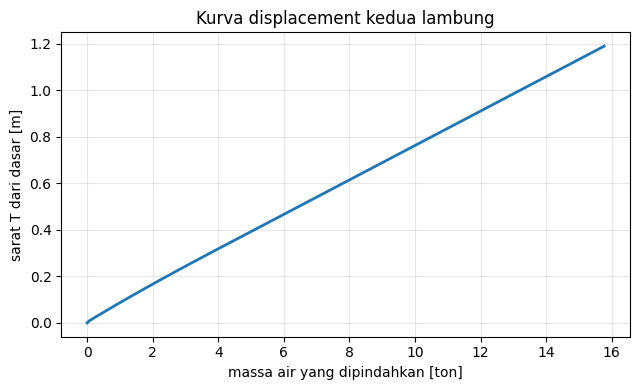

In [14]:
dx = STEP * CELL_CM / 100             # jarak antar titik ukur [m]
HO = 1025.0; G_ACC = 9.81            # air laut [kg/m³]; percepatan gravitasi [m/s²]
V1, V2 = simpson(A1, dx=dx), simpson(A2, dx=dx); Vt = V1 + V2
print(f"Volume total (dari Langkah 3) : {Vt:.3f} m³")
for nama, rho in [("air laut", 1025.0), ("air tawar", 1000.0)]:
    print(f"Terbenam penuh, {nama:9s} (ρ={rho:6.0f}): massa air = {rho*Vt:8.0f} kg = {rho*Vt/1000:5.2f} ton | gaya apung = {rho*G_ACC*Vt/1000:6.1f} kN")

B = D.max() - D                        # tinggi dasar lambung dari titik terendah [m]
def V_tercelup(T, W):
    s = np.clip(T - B, 0, D)           # kedalaman tercelup di tiap x
    return simpson(W * s, dx=dx)
Ts = np.linspace(0, D.max(), 121)
Vc = np.array([V_tercelup(T, W1) + V_tercelup(T, W2) for T in Ts])
print(f"\nCek: V(T = {D.max():.3f} m) = {Vc[-1]:.3f} m³  (harus = volume total {Vt:.3f})")
print(f"\n{'T (m)':>6} {'V (m³)':>8} {'massa air (ton)':>16}")
for T in [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]:
    v = V_tercelup(T, W1) + V_tercelup(T, W2); print(f"{T:6.2f} {v:8.3f} {RHO*v/1000:16.2f}")

plt.figure(figsize=(6.5, 4)); plt.plot(Vc*RHO/1000, Ts, lw=2)
plt.xlabel("massa air yang dipindahkan [ton]"); plt.ylabel("sarat T dari dasar [m]")
plt.title("Kurva displacement kedua lambung"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretasi**
- Bila kedua lambung terbenam penuh, volume 15,383 m³ memindahkan air laut seberat
  **≈ 15,77 ton** (gaya apung ≈ **154,7 kN**). Dengan air tawar hasilnya ≈ 15,38 ton
  (150,9 kN), lebih kecil sekitar 2,5% karena massa jenisnya lebih kecil.
- **Pengecekan berhasil:** pada sarat T = d_maks = 1,189 m, V(T) = 15,383 m³, sama persis
  dengan volume total di Langkah 3. Artinya rumus kedalaman tercelup s(x;T) dan
  integralnya sudah benar.
- **Bentuk kurva displacement.** Dari T = 0,4 sampai 1,0 m, volume bertambah hampir linear,
  ≈ 13,2 m³ per meter sarat. Nilai ini sama dengan luas bidang air (waterplane) kedua
  lambung ≈ 13,2 m², yaitu 2 lambung × ±6,9 m × ±0,96 m. Lambung berdinding tegak
  dengan lebar hampir konstan memang membuat volume naik hampir lurus terhadap sarat.
- Pada sarat rendah (T < 0,4 m) pertambahan volume sedikit lebih kecil (≈ 11,9 m³ per
  meter pada 0 sampai 0,2 m), karena dasar buritan melengkung naik sehingga luas bidang
  air belum penuh.
- Setiap tambahan sarat 1 cm memindahkan ≈ 0,13 m³ air, atau ≈ 135 kg
  (≈ 13,5 ton per meter sarat). Ini ukuran seberapa sensitif sarat kapal terhadap beban.
- Angka 15,77 ton adalah **batas atas** (lambung terbenam sampai geladak), bukan sarat
  sebenarnya. Kapal mengapung pada sarat saat massa air yang dipindahkan sama dengan
  massa kapal. Kurva m(T) inilah yang dipakai di Langkah 5 untuk mencari load line
  tanpa beban.
- Asumsi: air laut ρ = 1025 kg/m³ (ganti `RHO` bila dosen menentukan lain), dan
  ketebalan dinding fiberglass tidak dikurangkan dari volume.

## 5. Massa Kapal dan Load Line Tanpa Beban

**Tujuan:** menaksir massa kapal (tanpa beban), lalu mencari sarat tempat kapal
mengapung (*load line*): yaitu sarat T saat massa air yang dipindahkan sama dengan
massa kapal.

**Massa kapal ditaksir dari cangkang fiberglass:**

$$M_{kapal} = \rho_{fg}\; t \; A_{cangkang}$$

dengan $A_{cangkang}$ = luas dasar + sisi + geladak + sekat ujung (kedua lambung).
Luas permukaan dihitung dengan integral, memakai faktor panjang busur karena
permukaannya miring/melengkung:

$$A_{dasar}=\int w\sqrt{1+b'^2}\,dx,\quad A_{sisi}=2\int d\sqrt{1+\left(\tfrac{w'}{2}\right)^2}dx,\quad A_{geladak}=\int w\,dx$$

**Asumsi (bisa diubah):** tebal laminasi t = 6 mm, massa jenis laminasi fiberglass
ρ_fg = 1600 kg/m³, lambung tertutup geladak dengan sekat di kedua ujung, tanpa beban
dan tanpa massa tambahan (`M_EXTRA = 0`).

**Load line:** karena m_air(T) = ρ·V(T) naik monoton (Langkah 4), sarat T dicari dengan
interpolasi dari kurva displacement sehingga m_air(T) = M_kapal.

             dasar  geladak    sisi   sekat   total  [m²]
lambung 1     6.66    6.62   16.79    1.47   31.54
lambung 2     6.67    6.63   16.79    1.45   31.55

Luas cangkang total = 63.09 m² | massa per m² = 9.6 kg/m²
Massa cangkang = 606 kg | massa kapal (tanpa beban) = 606 kg
Load line (sarat tanpa beban)  T = 5.4 cm dari dasar | lambung bebas = 1.134 m
V tercelup = 0.591 m³ (3.8% volume lambung)

tebal (mm)  massa (kg)  sarat (cm)
         4         404         3.8
         6         606         5.4
         8         808         7.1
        10        1009         8.8


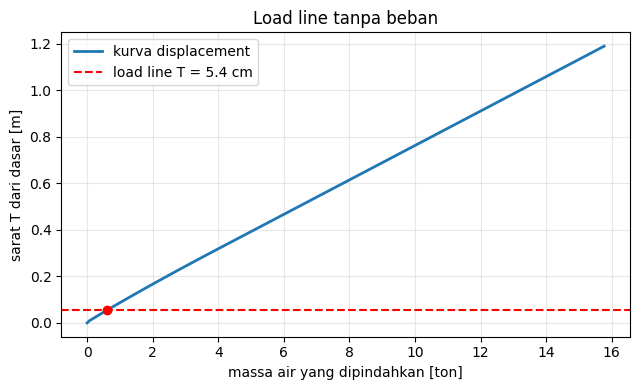

In [15]:
T_FG, RHO_FG, M_EXTRA = 0.006, 1600.0, 0.0   # tebal [m], massa jenis laminasi [kg/m³], massa tambahan [kg]

k = int(round(1.0/STEP)); xc = xm[::k]        # titik tiap 1 kotak (turunan lebih halus)
def luas_cangkang(W):
    Wc, Dc, Bc = W[::k], D[::k], B[::k]
    dW, dB = np.gradient(Wc, xc), np.gradient(Bc, xc)
    dasar   = simpson(Wc*np.sqrt(1 + dB**2), x=xc)
    geladak = simpson(Wc, x=xc)
    sisi    = 2*simpson(Dc*np.sqrt(1 + (dW/2)**2), x=xc)
    sekat   = Wc[0]*Dc[0] + Wc[-1]*Dc[-1]
    return dasar, geladak, sisi, sekat

print(f"{'':10s} {'dasar':>7} {'geladak':>8} {'sisi':>7} {'sekat':>7} {'total':>7}  [m²]")
tot = 0
for nama, W in [("lambung 1", W1), ("lambung 2", W2)]:
    p = luas_cangkang(W); tot += sum(p)
    print(f"{nama:10s} " + " ".join(f"{v:7.2f}" for v in p) + f" {sum(p):7.2f}")

M_shell = RHO_FG*T_FG*tot; M_kapal = M_shell + M_EXTRA
print(f"\nLuas cangkang total = {tot:.2f} m² | massa per m² = {RHO_FG*T_FG:.1f} kg/m²")
print(f"Massa cangkang = {M_shell:.0f} kg | massa kapal (tanpa beban) = {M_kapal:.0f} kg")

m_curve = RHO*Vc                               # massa air yang dipindahkan vs sarat (Langkah 4)
T_load = np.interp(M_kapal, m_curve, Ts)
print(f"Load line (sarat tanpa beban)  T = {T_load*100:.1f} cm dari dasar | lambung bebas = {(D.max()-T_load):.3f} m")
print(f"V tercelup = {M_kapal/RHO:.3f} m³ ({M_kapal/RHO/Vc[-1]*100:.1f}% volume lambung)")

print(f"\n{'tebal (mm)':>10} {'massa (kg)':>11} {'sarat (cm)':>11}")
for t in [0.004, 0.006, 0.008, 0.010]:
    M = RHO_FG*t*tot + M_EXTRA; print(f"{t*1000:10.0f} {M:11.0f} {np.interp(M, m_curve, Ts)*100:11.1f}")

plt.figure(figsize=(6.5, 4)); plt.plot(m_curve/1000, Ts, lw=2, label="kurva displacement")
plt.axhline(T_load, color="red", ls="--", label=f"load line T = {T_load*100:.1f} cm")
plt.plot(M_kapal/1000, T_load, "ro")
plt.xlabel("massa air yang dipindahkan [ton]"); plt.ylabel("sarat T dari dasar [m]")
plt.title("Load line tanpa beban"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

**Interpretasi**
- **Luas cangkang.** Tiap lambung ≈ 31,5 m² (dasar 6,66 + geladak 6,62 + sisi 16,79 + sekat
  ujung 1,47 m²), total kedua lambung **≈ 63,09 m²**. Sisi mendominasi (≈ 53%) karena
  lambung dalam (≈ 1,19 m). Selisih antara lambung 1 dan 2 hanya ≈ 0,01 m², sesuai
  kesimpulan bahwa keduanya identik.
- **Massa kapal.** Dengan laminasi 6 mm dan ρ = 1600 kg/m³, tiap m² cangkang bermassa
  9,6 kg, sehingga massa cangkang = **≈ 606 kg**. Inilah massa kapal tanpa beban pada model ini.
- **Load line tanpa beban.** Massa air yang dipindahkan harus sama dengan massa kapal,
  yaitu 606 kg ≈ 0,591 m³ air laut. Sarat yang memenuhi itu **T ≈ 5,4 cm** dari dasar,
  dengan lambung bebas (freeboard) ≈ **1,134 m**. Hanya ≈ 3,8% volume lambung yang tercelup.
- **Kapal sangat dangkal sarat.** Gaya apung maksimum ≈ 15,8 ton (Langkah 4), jauh di atas
  berat cangkang 0,6 ton. Itu bukan keanehan: lambung berukuran besar tetapi dindingnya tipis.
  Artinya hampir seluruh volume lambung menjadi cadangan apung untuk beban (mesin, geladak,
  penumpang, perlengkapan).
- **Sensitivitas.** Tebal laminasi 4 → 10 mm mengubah massa 404 → 1009 kg dan sarat
  3,8 → 8,8 cm; kira-kira tiap +2 mm menambah ≈ 200 kg dan ≈ 1,7 cm sarat.
  Sarat tanpa beban ternyata kecil dan tidak terlalu peka terhadap asumsi tebal.
- **Batasan.** Ini taksiran **batas bawah** massa kapal karena hanya cangkang yang dihitung:
  rangka, geladak penghubung, mesin, dan perlengkapan belum masuk (`M_EXTRA = 0`).
  Bila massa tambahan diketahui, cukup isi `M_EXTRA` dan load line bergeser otomatis.
  Tebal 6 mm dan ρ = 1600 kg/m³ adalah asumsi, bukan data soal.
- Massa kapal dan sarat ini dipakai di Langkah 6 untuk menghitung titik berat (CoM) dan
  pusat apung (CoB).

## 6. Pusat Massa (CoM) dan Pusat Apung (CoB)

**Tujuan:** menentukan titik tangkap berat kapal (CoM, titik G) dan titik tangkap
gaya apung (CoB, titik B). Keduanya dihitung dengan teori integral momen.

**Teori:** pusat massa adalah rata-rata posisi yang dibobot massa (momen dibagi massa):

$$x_G=\frac{\int x\,dm}{\int dm},\qquad z_G=\frac{\int z\,dm}{\int dm}$$

- **CoM (cangkang saja):** massa tersebar sebagai kerapatan per panjang λ(x) = σ·(luas
  per panjang) dengan σ = ρ_fg·t, di masing-masing bagian: dasar (tinggi z = b(x)),
  geladak (z = d_maks), sisi (z = d_maks − d/2), dan sekat ujung sebagai massa titik.
- **CoB:** pusat volume air yang dipindahkan pada load line T (Langkah 5). Di tiap x,
  bagian tercelup berupa persegi panjang dari z = b(x) sampai b(x) + s(x):

$$x_B=\frac{\int x\,w\,s\,dx}{\int w\,s\,dx},\qquad z_B=\frac{\int w\,s\,\big(b+\tfrac{s}{2}\big)dx}{\int w\,s\,dx}$$

**Sistem koordinat:** x dari garis *reserve buoyancy* buritan (searah haluan), y dari
garis tengah di antara dua lambung, z dari titik terendah dasar lambung (ke atas).
Tanpa massa tambahan (`M_EXTRA = 0`), sesuai Langkah 5.

            massa (kg)   xG (m)   zG (m) |   V (m³)   xB (m)   zB (m)
lambung 1        302.8    3.599    0.608 |   0.2958    3.868    0.029
lambung 2        302.9    3.593    0.608 |   0.2951    3.858    0.029

Massa kapal (hasil integral momen) = 605.7 kg (Langkah 5: 605.7 kg)
CoM kapal : x = 3.596 m (49.9% L) | y = +0.000 m | z = 0.608 m
CoB kapal : x = 3.863 m (53.6% L) | y = -0.002 m | z = 0.029 m
Selisih xB - xG = +0.267 m | momen trim = +1.59 kN·m
Jarak vertikal zG - zB = 0.579 m


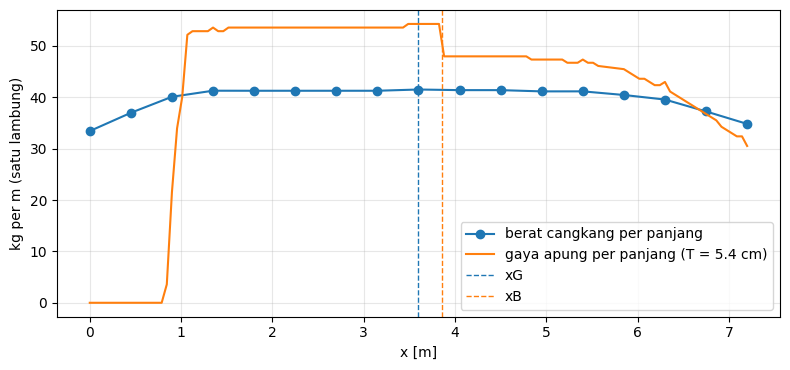

In [16]:
sep = (CY2 - CY1) / S * CELL_CM / 100          # jarak antar pusat lambung [m]
y_h = {1: -sep/2, 2: +sep/2}                    # posisi y tiap lambung dari garis tengah kapal
sigma = RHO_FG * T_FG                           # massa per m² cangkang [kg/m²]
Dm = D.max()

def cangkang_momen(W):
    Wc, Dc, Bc = W[::k], D[::k], B[::k]
    dW, dB = np.gradient(Wc, xc), np.gradient(Bc, xc)
    lam = {"dasar":   (sigma*Wc*np.sqrt(1 + dB**2), Bc),                       # (kg/m, tinggi z)
           "geladak": (sigma*Wc, Dm*np.ones_like(Wc)),
           "sisi":    (sigma*2*Dc*np.sqrt(1 + (dW/2)**2), Dm - Dc/2)}
    m = mx = mz = 0.0
    for l, zz in lam.values():
        m += simpson(l, x=xc); mx += simpson(l*xc, x=xc); mz += simpson(l*zz, x=xc)
    for j in (0, -1):                                                          # sekat ujung (massa titik)
        ms = sigma*Wc[j]*Dc[j]; m += ms; mx += ms*xc[j]; mz += ms*(Dm - Dc[j]/2)
    return m, mx, mz

def apung(W, T):
    s = np.clip(T - B, 0, D)
    V = simpson(W*s, dx=dx)
    return V, simpson(W*s*xm, dx=dx)/V, simpson(W*s*(B + s/2), dx=dx)/V

M = MX = MY = MZ = 0.0; Vt = VX = VY = VZ = 0.0
print(f"{'':10s} {'massa (kg)':>11} {'xG (m)':>8} {'zG (m)':>8} | {'V (m³)':>8} {'xB (m)':>8} {'zB (m)':>8}")
for i, W in [(1, W1), (2, W2)]:
    m, mx, mz = cangkang_momen(W); V, xb, zb = apung(W, T_load)
    M += m; MX += mx; MY += m*y_h[i]; MZ += mz
    Vt += V; VX += V*xb; VY += V*y_h[i]; VZ += V*zb
    print(f"lambung {i}  {m:11.1f} {mx/m:8.3f} {mz/m:8.3f} | {V:8.4f} {xb:8.3f} {zb:8.3f}")

xG, yG, zG = MX/M, MY/M, MZ/M
xB, yB, zB = VX/Vt, VY/Vt, VZ/Vt
L = xm[-1]
print(f"\nMassa kapal (hasil integral momen) = {M:.1f} kg (Langkah 5: {M_kapal:.1f} kg)")
print(f"CoM kapal : x = {xG:.3f} m ({xG/L*100:.1f}% L) | y = {yG:+.3f} m | z = {zG:.3f} m")
print(f"CoB kapal : x = {xB:.3f} m ({xB/L*100:.1f}% L) | y = {yB:+.3f} m | z = {zB:.3f} m")
print(f"Selisih xB - xG = {xB-xG:+.3f} m | momen trim = {M*9.81*(xB-xG)/1000:+.2f} kN·m")
print(f"Jarak vertikal zG - zB = {zG-zB:.3f} m")

# visual: sebaran berat vs gaya apung per panjang (satu lambung)
Wc, Dc, Bc = W1[::k], D[::k], B[::k]
dW, dB = np.gradient(Wc, xc), np.gradient(Bc, xc)
lam_berat = sigma*(Wc*np.sqrt(1 + dB**2) + Wc + 2*Dc*np.sqrt(1 + (dW/2)**2))
lam_apung = RHO*W1*np.clip(T_load - B, 0, D)
plt.figure(figsize=(8, 3.8))
plt.plot(xc, lam_berat, "o-", label="berat cangkang per panjang")
plt.plot(xm, lam_apung, label=f"gaya apung per panjang (T = {T_load*100:.1f} cm)")
plt.axvline(xG, color="C0", ls="--", lw=1, label="xG"); plt.axvline(xB, color="C1", ls="--", lw=1, label="xB")
plt.xlabel("x [m]"); plt.ylabel("kg per m (satu lambung)"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

**Interpretasi**
- **Massa:** integral momen memberi massa kapal **605,7 kg**, sama dengan Langkah 5.
  Ini membuktikan model massa tersebar (dasar + geladak + sisi + sekat) konsisten.
- **CoM (titik G):** x = **3,596 m** (49,9% panjang), y ≈ 0, z = **0,608 m**.
  x berada hampir tepat di tengah karena cangkang simetris depan-belakang, hanya sedikit
  lebih ringan di ujung. z ≈ 51% dari kedalaman lambung (1,189 m), wajar untuk
  cangkang tertutup yang dasarnya di z = 0, geladaknya di z = 1,189 m, dan sisinya
  berpusat di tengah.
- **CoB (titik B):** x = **3,863 m** (53,6% panjang), y ≈ −0,002 m, z = **0,029 m**.
  z ≈ setengah sarat (5,4 cm / 2 ≈ 2,7 cm), sesuai bentuk bagian tercelup yang tipis
  seperti pelat. y ≈ 0 menandakan kapal simetris kiri-kanan, sehingga tidak ada
  kecenderungan miring ke samping (heel).
- **Grafik berat vs gaya apung:** gaya apung nol di buritan karena dasar melengkung naik
  di atas air, lalu mendatar ≈ 48–54 kg/m, sedangkan berat ≈ 41 kg/m. Loncatan dan gerigi
  pada kurva apung adalah noise kuantisasi piksel (±0,6 cm) yang tampak besar karena sarat
  hanya 5,4 cm; bukan perubahan bentuk lambung.
- **Keseimbangan longitudinal:** xB − xG = **+0,267 m** (≈ 3,7% panjang), momen trim
  ≈ 1,59 kN·m. Pada keseimbangan sejati titik B segaris vertikal dengan titik G. Selisih
  ini menunjukkan model "lunas rata" tidak sepenuhnya seimbang: gaya apung bekerja
  lebih ke haluan daripada berat, sehingga kapal cenderung sedikit mengangkat haluan dan
  menurunkan buritan (trim buritan) sampai xB bergeser ke belakang. Karena momennya kecil,
  koreksi trim yang sebenarnya juga kecil.
- **zG − zB = 0,579 m:** titik G berada di atas titik B. Ini belum cukup untuk menilai
  stabilitas, karena stabilitas butuh tinggi metasenter (bukan bagian tugas ini).
- **Batasan:** CoM hanya cangkang (`M_EXTRA = 0`); beban, mesin, dan geladak penghubung
  akan menggeser G. CoB dihitung pada sarat rata tanpa trim.

## 7. Ilustrasi 3D: Lambung, Load Line, CoM dan CoB

**Tujuan:** memvisualisasikan seluruh hasil Langkah 1–6 dalam satu model: bentuk
kedua lambung (dari w(x) dan d(x)), bidang air pada load line tanpa beban, serta
posisi titik berat (G) dan pusat apung (B).

**Cara membuat:**
1. Lambung dibangun dari potongan persegi panjang w(x)×d(x), persis seperti yang
   diintegralkan. Terdiri dari sisi, dasar (melengkung naik di buritan), geladak,
   dan sekat ujung.
2. Bidang air digambar pada ketinggian T = load line, dihitung dari titik terendah dasar.
3. Titik G (merah) dan B (kuning) digambar pada koordinat hasil Langkah 6.
4. Tampak samping dan tampak depan dibuat sebagai pengecekan skala yang sebenarnya.

*Catatan:* sumbu z pada model 3D sengaja diperbesar agar lambung terlihat jelas.
Tampak samping dan depan memakai skala yang sama (1:1).

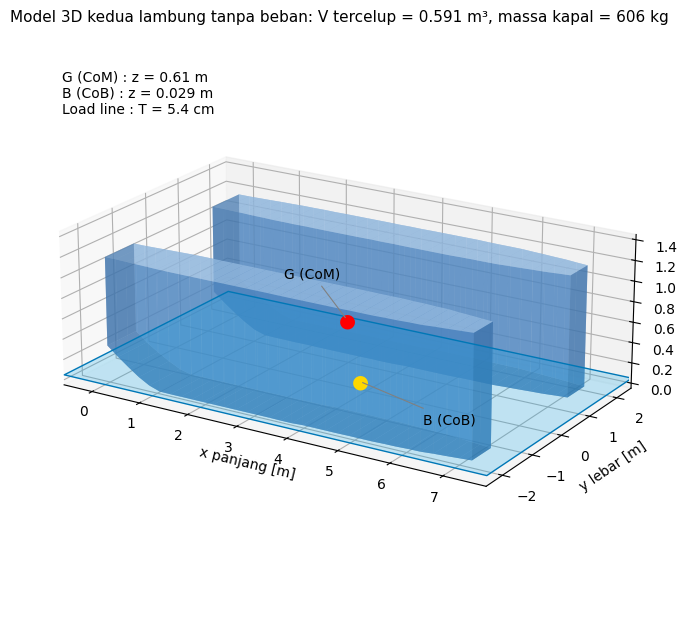

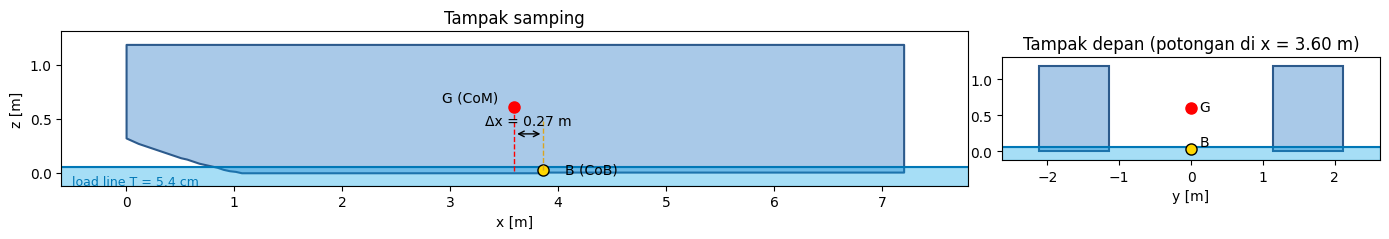

In [20]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mpl_toolkits.mplot3d import proj3d

sub = slice(None, None, 4)                          # titik lebih jarang untuk gambar 3D
X, Wv = xm[sub], {1: W1[sub], 2: W2[sub]}
Dv, Bv = D[sub], B[sub]
WARNA = {"sisi": "#4f86c0", "dasar": "#2c5a8c", "geladak": "#a9c9e8", "ujung": "#3a6ea5"}

def faces_lambung(yc, Wl):
    f = {"sisi": [], "dasar": [], "geladak": [], "ujung": []}
    for i in range(len(X) - 1):
        x0, x1 = X[i], X[i+1]
        for sg in (-1, 1):
            f["sisi"].append([(x0, yc+sg*Wl[i]/2, Bv[i]), (x1, yc+sg*Wl[i+1]/2, Bv[i+1]),
                              (x1, yc+sg*Wl[i+1]/2, Dm), (x0, yc+sg*Wl[i]/2, Dm)])
        f["dasar"].append([(x0, yc-Wl[i]/2, Bv[i]), (x1, yc-Wl[i+1]/2, Bv[i+1]),
                           (x1, yc+Wl[i+1]/2, Bv[i+1]), (x0, yc+Wl[i]/2, Bv[i])])
        f["geladak"].append([(x0, yc-Wl[i]/2, Dm), (x1, yc-Wl[i+1]/2, Dm),
                             (x1, yc+Wl[i+1]/2, Dm), (x0, yc+Wl[i]/2, Dm)])
    for j in (0, -1):
        f["ujung"].append([(X[j], yc-Wl[j]/2, Bv[j]), (X[j], yc+Wl[j]/2, Bv[j]),
                           (X[j], yc+Wl[j]/2, Dm), (X[j], yc-Wl[j]/2, Dm)])
    return f

# ---------- Gambar 1: model 3D ----------
fig = plt.figure(figsize=(12, 7.5))
ax = fig.add_subplot(111, projection="3d")
for i in (1, 2):
    for jenis, fc in faces_lambung(y_h[i], Wv[i]).items():
        ax.add_collection3d(Poly3DCollection(fc, facecolor=WARNA[jenis], edgecolor="none", alpha=.6))
# bidang air pada load line
xa, xb_ = -0.6, L + 0.6; ya, yb_ = -sep/2 - 0.9, sep/2 + 0.9
ax.add_collection3d(Poly3DCollection([[(xa, ya, T_load), (xb_, ya, T_load), (xb_, yb_, T_load), (xa, yb_, T_load)]],
                                     facecolor="#00a2e8", edgecolor="#0077b6", alpha=.22))
ax.set_xlim(-0.6, L + 0.6); ax.set_ylim(ya, yb_); ax.set_zlim(-0.05, 1.45)
ax.set_box_aspect((L + 1.2, sep + 1.8, 2.8)); ax.view_init(20, -58)
ax.set_xlabel("x panjang [m]"); ax.set_ylabel("y lebar [m]"); ax.set_zlabel("z tinggi [m]")
ax.text2D(0.02, 0.93, f"G (CoM) : z = {zG:.2f} m\nB (CoB) : z = {zB:.3f} m\nLoad line : T = {T_load*100:.1f} cm",
          transform=ax.transAxes, fontsize=10, va="top")

# titik G dan B digambar di atas semua bidang
fig.canvas.draw()
def titik(x, y, z, teks, warna, dx_, dy_):
    px, py, _ = proj3d.proj_transform(x, y, z, ax.get_proj())
    ax.annotate("●", (px, py), ha="center", va="center", fontsize=14, color=warna, zorder=20)
    ax.annotate(teks, (px, py), xytext=(dx_, dy_), textcoords="offset points", fontsize=10, color="k",
                arrowprops=dict(arrowstyle="-", color="gray", lw=.8), zorder=21)
titik(xG, yG, zG, "G (CoM)", "red", -45, 30)
titik(xB, yB, zB, "B (CoB)", "gold", 45, -30)
ax.set_title(f"Model 3D kedua lambung tanpa beban: V tercelup = {Vt:.3f} m³, massa kapal = {M:.0f} kg", fontsize=11)
plt.show()

# ---------- Gambar 2: tampak samping dan tampak depan ----------
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.4, 1]})
a.fill_between(xm, B, Dm, color="#a9c9e8", ec="#2c5a8c", lw=1.5)
a.fill_between([-0.6, L+0.6], -0.12, T_load, color="#00a2e8", alpha=.35)
a.axhline(T_load, color="#0077b6", lw=1.5)
a.plot(xG, zG, "o", color="red", ms=8); a.plot(xB, zB, "o", color="gold", mec="k", ms=8)
a.text(xG-0.15, zG+0.05, "G (CoM)", ha="right"); a.text(xB+0.2, zB, "B (CoB)", ha="left", va="center")
a.text(-0.5, -0.08, f"load line T = {T_load*100:.1f} cm", ha="left", va="center", fontsize=9, color="#0077b6")
a.plot([xG, xG], [zG, 0], "r--", lw=1); a.plot([xB, xB], [zB, zB+.45], ls="--", color="goldenrod", lw=1)
a.annotate("", xy=(xB, .36), xytext=(xG, .36), arrowprops=dict(arrowstyle="<->"))
a.text((xG+xB)/2, .44, f"Δx = {xB-xG:.2f} m", ha="center")
a.set_xlim(-0.6, L+0.6); a.set_ylim(-0.12, Dm+0.12); a.set_aspect("equal"); a.set_title("Tampak samping")
a.set_xlabel("x [m]"); a.set_ylabel("z [m]")
im = int(np.argmin(np.abs(xm - xG)))
for i, Wl in [(1, W1), (2, W2)]:
    b.add_patch(plt.Rectangle((y_h[i]-Wl[im]/2, B[im]), Wl[im], D[im], fc="#a9c9e8", ec="#2c5a8c", lw=1.5))
b.fill_between([-sep/2-1, sep/2+1], -0.12, T_load, color="#00a2e8", alpha=.35); b.axhline(T_load, color="#0077b6", lw=1.5)
b.plot(yG, zG, "o", color="red", ms=8); b.plot(yB, zB, "o", color="gold", mec="k", ms=8)
b.text(yG+0.12, zG, "G", va="center"); b.text(yB+0.12, zB+0.1, "B", va="center")
b.set_xlim(-sep/2-1, sep/2+1); b.set_ylim(-0.12, Dm+0.12); b.set_aspect("equal")
b.set_title(f"Tampak depan (potongan di x = {xm[im]:.2f} m)"); b.set_xlabel("y [m]")
plt.tight_layout(); plt.show()

**Interpretasi**
- **Bentuk model.** Kedua lambung berbentuk balok panjang dengan lebar ≈ 0,97 m dan tinggi
  ≈ 1,19 m, berjarak ≈ 3,26 m. Di ujung kiri (buritan) dasar lambung melengkung naik,
  sedangkan di bagian tengah dan haluan dasarnya datar. Ini sesuai data d(x) di Langkah 2.
  Sumbu z pada gambar sengaja diperbesar agar jelas; proporsi aslinya lebih pipih
  (tinggi 1,19 m terhadap panjang 7,2 m).
- **Garis air (load line).** Bidang air berada pada T = 5,4 cm dari dasar, sehingga hampir
  seluruh lambung berada di atas air. Hanya lapisan tipis dasar yang tercelup
  (V tercelup = 0,591 m³, sekitar 3,8% dari volume lambung), dan lambung bebas
  ≈ 1,13 m. Ini sesuai gambaran Langkah 5: cangkang hanya 606 kg, sedangkan lambungnya
  mampu memikul beban belasan ton.
- **Titik G (CoM).** G berada di z = 0,61 m, kira-kira setengah tinggi lambung, tepat di
  tengah di antara dua lambung (y ≈ 0). Letaknya tinggi karena massa cangkang tersebar di
  dasar, sisi, dan geladak.
- **Titik B (CoB).** B berada di z = 0,029 m, dekat bidang air, karena volume yang
  tercelup hanya lapisan tipis di dasar. Posisi y ≈ 0 menunjukkan simetri kiri-kanan,
  jadi tidak ada kecenderungan miring ke samping.
- **Hubungan G dan B.** G berada ≈ 0,58 m di atas B. Dari sisi x, B terletak sedikit
  lebih ke haluan daripada G (Δx ≈ 0,27 m, ≈ 3,7% panjang), sehingga pada model sarat
  rata masih ada momen trim kecil ≈ 1,6 kN·m (Langkah 6). Pada kondisi

## 8. Ringkasan Hasil, Sensitivitas, dan Kesimpulan

**Tujuan:** menyatukan semua hasil Langkah 1–7 dalam satu ringkasan, lalu menguji
seberapa kuat hasil itu terhadap asumsi terpenting: skala grid dan ketelitian digitalisasi.

**Hukum skala:** bila 1 kotak = f × 45 cm, maka
- volume ∝ f³,
- luas cangkang dan massa cangkang ∝ f²,
- posisi CoM/CoB ∝ f,
- sarat T dicari ulang dari kurva displacement: ρ·V(T/f) = M_kapal/f, lalu T = f·(hasilnya).

**Ketidakpastian digitalisasi:** tepi lambung diukur ±1 piksel (≈ 0,6 cm). Kasus terburuk
adalah kedua tepi meleset 1 piksel searah (lebar ±2 piksel, kedalaman ±1 piksel).

In [21]:
V1, V2 = simpson(A1, dx=dx), simpson(A2, dx=dx); V_full = V1 + V2

print("=" * 60); print(" RINGKASAN HASIL (1 kotak = 45 cm)"); print("=" * 60)
print(f"Panjang lambung dihitung        : {L:.2f} m   | lebar maks {W1.max():.3f} m | kedalaman maks {D.max():.3f} m")
print(f"Volume lambung 1 / 2 (Simpson)  : {V1:.3f} / {V2:.3f} m³")
print(f"VOLUME KEDUA LAMBUNG            : {V_full:.3f} m³  = {V_full*1000:.0f} liter")
print(f"Massa air (terbenam penuh)      : {RHO*V_full/1000:.2f} ton  (air laut ρ = {RHO:.0f} kg/m³)")
print(f"Luas cangkang total             : {tot:.2f} m²  -> massa kapal tanpa beban = {M_kapal:.0f} kg")
print(f"Load line tanpa beban           : T = {T_load*100:.1f} cm | lambung bebas = {Dm-T_load:.3f} m")
print(f"CoM (G) : x = {xG:.3f} m, y = {yG:+.3f} m, z = {zG:.3f} m")
print(f"CoB (B) : x = {xB:.3f} m, y = {yB:+.3f} m, z = {zB:.3f} m")

# sensitivitas skala (V ~ f^3, luas & massa cangkang ~ f^2)
print(f"\n{'1 kotak (cm)':>12} {'V total (m³)':>13} {'massa kapal (kg)':>17} {'sarat T (cm)':>13}")
for s_cm in [40, 43, 45, 47, 50]:
    f = s_cm / CELL_CM
    Mk = M_kapal * f**2
    Tl = f * np.interp(M_kapal / f, m_curve, Ts)
    print(f"{s_cm:12d} {V_full*f**3:13.3f} {Mk:17.0f} {Tl*100:13.1f}")

# ketidakpastian digitalisasi: tepi bergeser 1 piksel (kasus terburuk, searah)
dw, dd = 2/S*CELL_CM/100, 1/S*CELL_CM/100
for tanda in (-1, +1):
    Vb = sum(simpson((Wl + tanda*dw)*(D + tanda*dd), dx=dx) for Wl in (W1, W2))
    print(f"Tepi bergeser {tanda:+d} piksel -> V total = {Vb:.3f} m³ ({(Vb/V_full-1)*100:+.1f}%)")

 RINGKASAN HASIL (1 kotak = 45 cm)
Panjang lambung dihitung        : 7.20 m   | lebar maks 0.974 m | kedalaman maks 1.189 m
Volume lambung 1 / 2 (Simpson)  : 7.704 / 7.679 m³
VOLUME KEDUA LAMBUNG            : 15.383 m³  = 15383 liter
Massa air (terbenam penuh)      : 15.77 ton  (air laut ρ = 1025 kg/m³)
Luas cangkang total             : 63.09 m²  -> massa kapal tanpa beban = 606 kg
Load line tanpa beban           : T = 5.4 cm | lambung bebas = 1.134 m
CoM (G) : x = 3.596 m, y = +0.000 m, z = 0.608 m
CoB (B) : x = 3.863 m, y = -0.002 m, z = 0.029 m

1 kotak (cm)  V total (m³)  massa kapal (kg)  sarat T (cm)
          40        10.804               479           5.4
          43        13.422               553           5.4
          45        15.383               606           5.4
          47        17.527               661           5.5
          50        21.102               748           5.5
Tepi bergeser -1 piksel -> V total = 15.089 m³ (-1.9%)
Tepi bergeser +1 piksel -> V total =

**Interpretasi**
- **Ringkasan.** Volume lambung 1 = 7,704 m³ dan lambung 2 = 7,679 m³ (beda ≈ 0,3%, jadi
  keduanya identik). **Volume kedua lambung = 15,383 m³ (≈ 15.383 liter).** Bila terbenam
  penuh, lambung memindahkan air laut seberat **≈ 15,77 ton**.
- **Massa dan load line.** Massa kapal tanpa beban (cangkang fiberglass 6 mm) ≈ **606 kg**,
  sehingga kapal mengapung pada sarat **T ≈ 5,4 cm** dengan lambung bebas ≈ 1,13 m.
  Titik berat G di (x = 3,60 m; z = 0,61 m) dan pusat apung B di (x = 3,86 m; z = 0,03 m),
  keduanya di y ≈ 0 (simetris kiri-kanan).
- **Sensitivitas skala (paling dominan).** Volume sebanding dengan skala³. Bila 1 kotak
  = 43 cm (bukan 45), volume turun ke 13,42 m³ (−12,7%); bila 50 cm, naik ke 21,10 m³
  (+37,2%). Karena itu hasil ini valid untuk skala 45 cm dari dosen.
- **Sarat tanpa beban hampir tidak bergantung skala.** Untuk skala 40–50 cm, T hanya
  berubah 5,4 → 5,5 cm. Penyebabnya: massa cangkang ∝ skala² dan luas bidang air
  ∝ skala² juga, sehingga skala saling meniadakan dan sarat tetap sekitar 5 cm.
- **Ketidakpastian digitalisasi.** Bila tepi lambung meleset 1 piksel (≈ 0,6 cm) searah,
  volume total berada di rentang 15,09–15,68 m³, yaitu **15,38 ± 0,30 m³ (± 1,9%)**.
  Ini kasus terburuk; galat acak antar-titik saling meniadakan sehingga galat
  sebenarnya lebih kecil.
- **Selisih antar-metode** (Trapesium, Simpson, Spline) di Langkah 3 hanya ≈ 0,05–0,15%,
  jauh lebih kecil daripada galat digitalisasi. Jadi ketelitian hasil dibatasi oleh
  pengukuran gambar dan skala, bukan oleh metode integrasi.

## Kesimpulan

1. **Volume kedua lambung ≈ 15,4 m³** (15,38 ± 0,30 m³; tiap lambung ≈ 7,7 m³), dihitung
   dengan integral numerik Simpson 1/3 dari A(x) = w(x)·d(x) sepanjang 7,2 m di antara
   garis *reserve buoyancy* (1 kotak = 45 cm). Trapesium dan Cubic Spline memberi hasil
   yang sama dalam ≈ 0,15%.
2. **Massa air yang dipindahkan** bila terbenam penuh ≈ **15,8 ton** (air laut, ρ = 1025
   kg/m³), gaya apung maksimum ≈ 155 kN.
3. **Massa kapal tanpa beban ≈ 606 kg** (taksiran cangkang fiberglass: luas 63,1 m²,
   tebal 6 mm, ρ = 1600 kg/m³). Dengan itu **load line tanpa beban T ≈ 5,4 cm** dari dasar
   dan lambung bebas ≈ 1,13 m.
4. **CoM (G)** pada x ≈ 3,60 m (49,9% panjang), z ≈ 0,61 m, y ≈ 0.
   **CoB (B)** pada x ≈ 3,86 m (53,6% panjang), z ≈ 0,03 m, y ≈ 0.
   G berada ≈ 0,58 m di atas B, dan B ≈ 0,27 m lebih ke haluan daripada G sehingga
   ada momen trim kecil (≈ 1,6 kN·m) pada model sarat rata.
5. **Batasan:** massa kapal hanya cangkang (tebal dan massa jenis adalah asumsi), beban dan
   mesin tidak dimasukkan, sarat dianggap rata, dan stabilitas belum dianalisis. Hasil paling
   peka terhadap skala grid (volume ∝ skala³) dan tepi lambung ±1 piksel (±1,9%).